# Predicting earthquake damage grade from building attributes — 2015 Gorkha (Nepal) earthquake
**Author:** Amrish Singh · singhamrish360@gmail.com · ORCID [0009-0005-1584-2504](https://orcid.org/0009-0005-1584-2504)

This notebook runs the full pipeline from `src/eq_damage.py` step by step: data loading & cleaning → EDA → baseline (logistic regression) and LightGBM → evaluation on a held-out test set → SHAP and permutation importance. Every number printed here is computed in this notebook and saved to `results/metrics.json`.

**Data:** Nepal Government (National Planning Commission / Central Bureau of Statistics) *Household Registration for Housing Reconstruction* survey, building-structure table (`csv_building_structure.csv`, 762,106 buildings), published via the 2015 Nepal Earthquake Open Data Portal (eq2015.npc.gov.np, built by Kathmandu Living Labs). The official portal was unreachable from the build machine, so the identical CSV was downloaded from a public GitHub mirror and pinned by SHA-256 (see README).

In [1]:
import sys, json, time, warnings
from pathlib import Path
sys.path.insert(0, str(Path('src').resolve()))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display
import eq_damage as E
T0 = time.time()

## 1. Load and clean
Post-earthquake columns (`count_floors_post_eq`, `height_ft_post_eq`, `condition_post_eq`, `technical_solution_proposed`) are **dropped to avoid target leakage**. `age_building = 999` is a sentinel for unknown age and is set to missing.

In [2]:
df, log = E.load_clean()
print(json.dumps(log, indent=1))
print('features (building attributes only):', len(E.STRUCT_FEATURES))
df[E.STRUCT_FEATURES + ['damage_grade']].head()

{
 "raw_rows": 762106,
 "raw_cols": 31,
 "dropped_missing_target": 12,
 "dropped_missing_features": 0,
 "age_999_set_to_nan": 3144,
 "clean_rows": 762094
}
features (building attributes only): 22


,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,...,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,damage_grade
0,1,9.0,288.0,9.0,Flat,Other,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,...,0,0,0,0,0,1,0,0,0,Grade 3
1,1,15.0,364.0,9.0,Flat,Other,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,...,0,0,0,0,0,1,0,0,0,Grade 5
2,1,20.0,384.0,9.0,Flat,Other,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,...,0,0,0,0,0,0,0,0,0,Grade 2
3,1,20.0,312.0,9.0,Flat,Other,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,...,0,0,0,0,0,0,0,0,0,Grade 2
4,1,30.0,308.0,9.0,Flat,Other,Bamboo/Timber-Light roof,Mud,Not applicable,Not attached,...,0,0,0,0,0,0,0,0,0,Grade 1


## 2. Exploratory data analysis

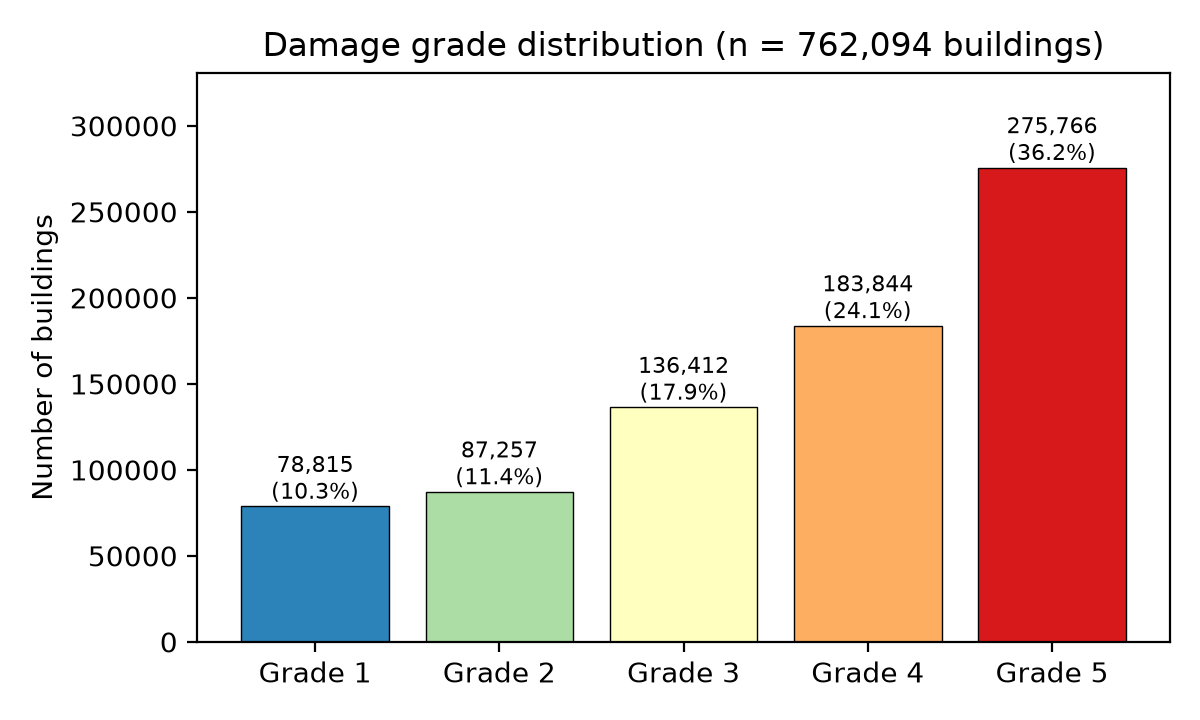

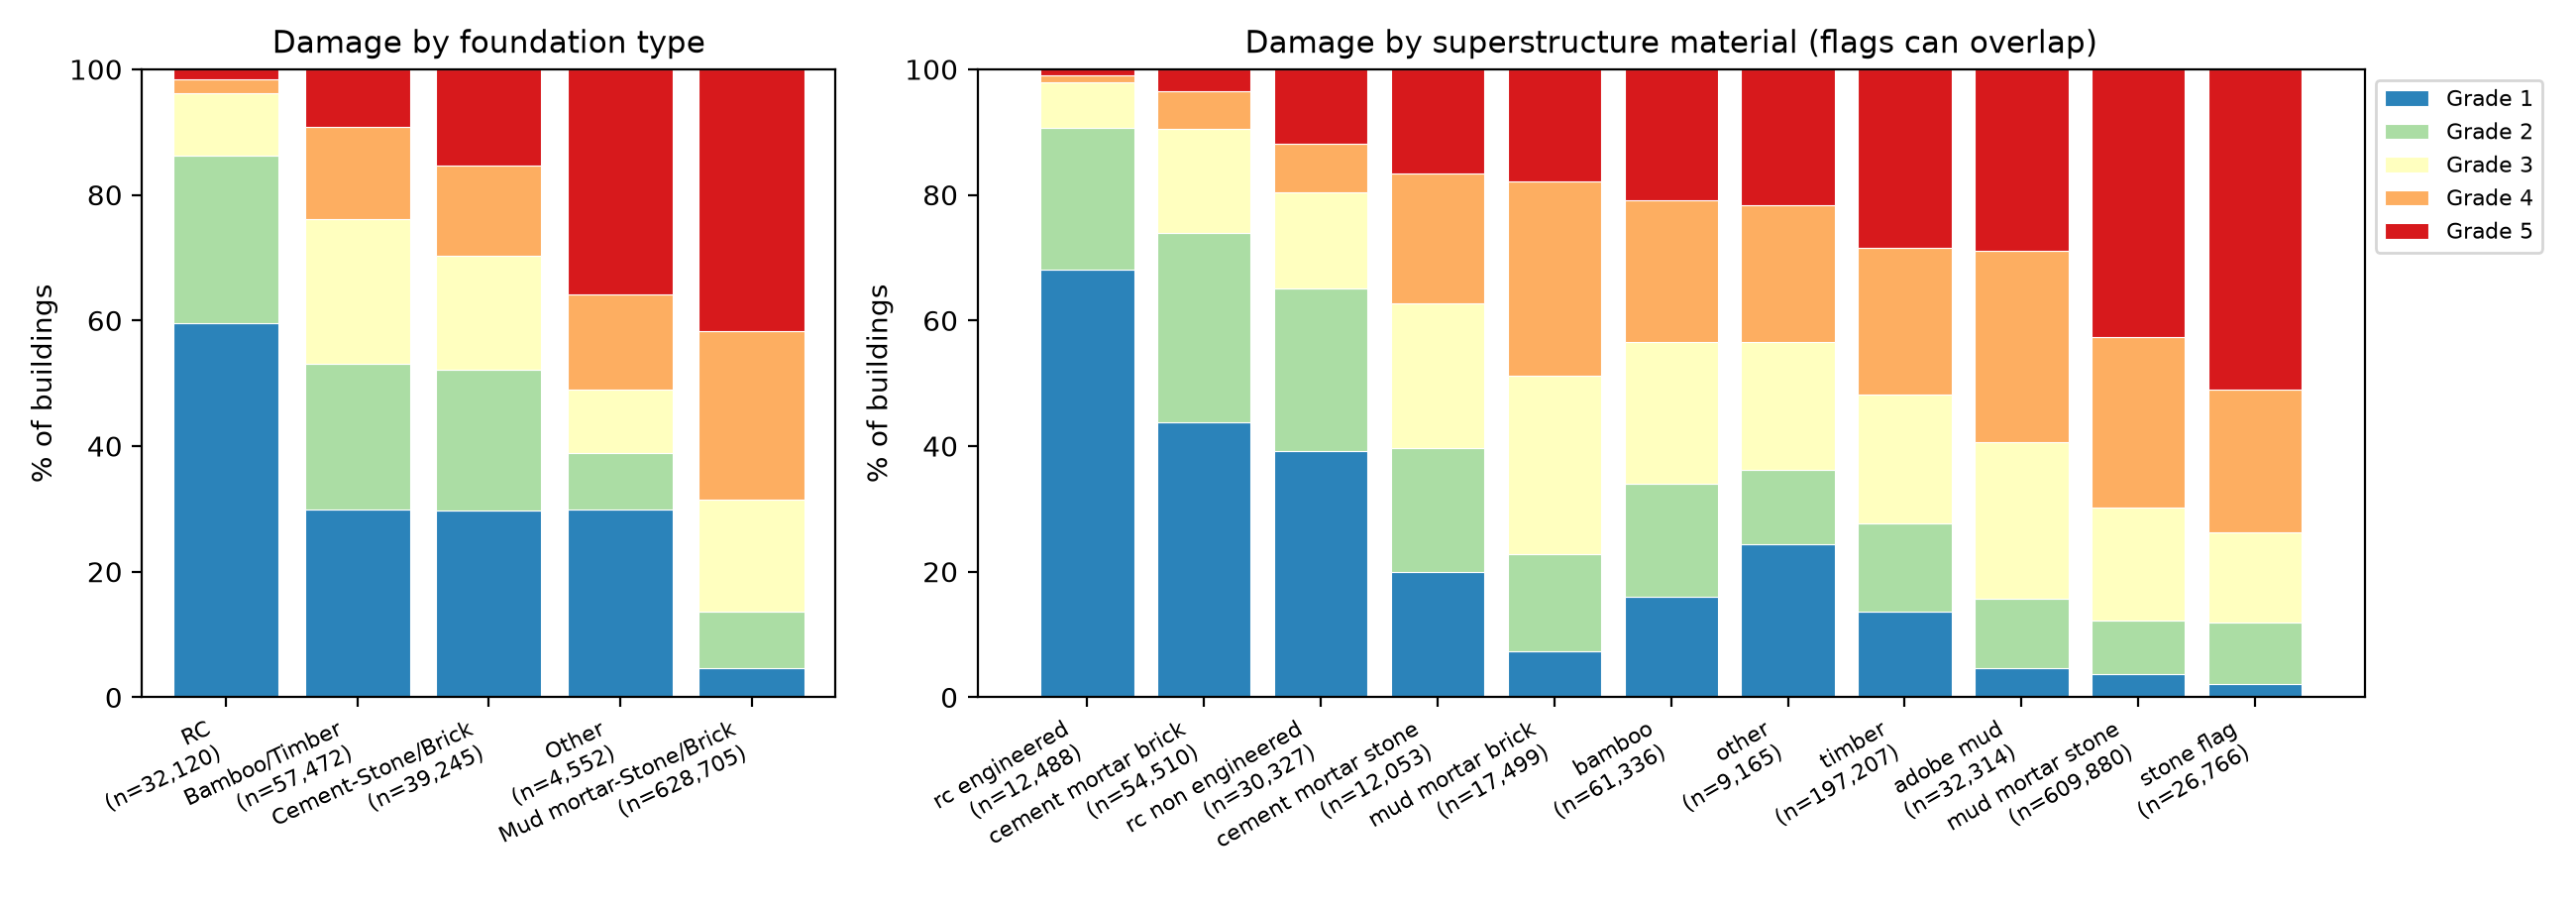

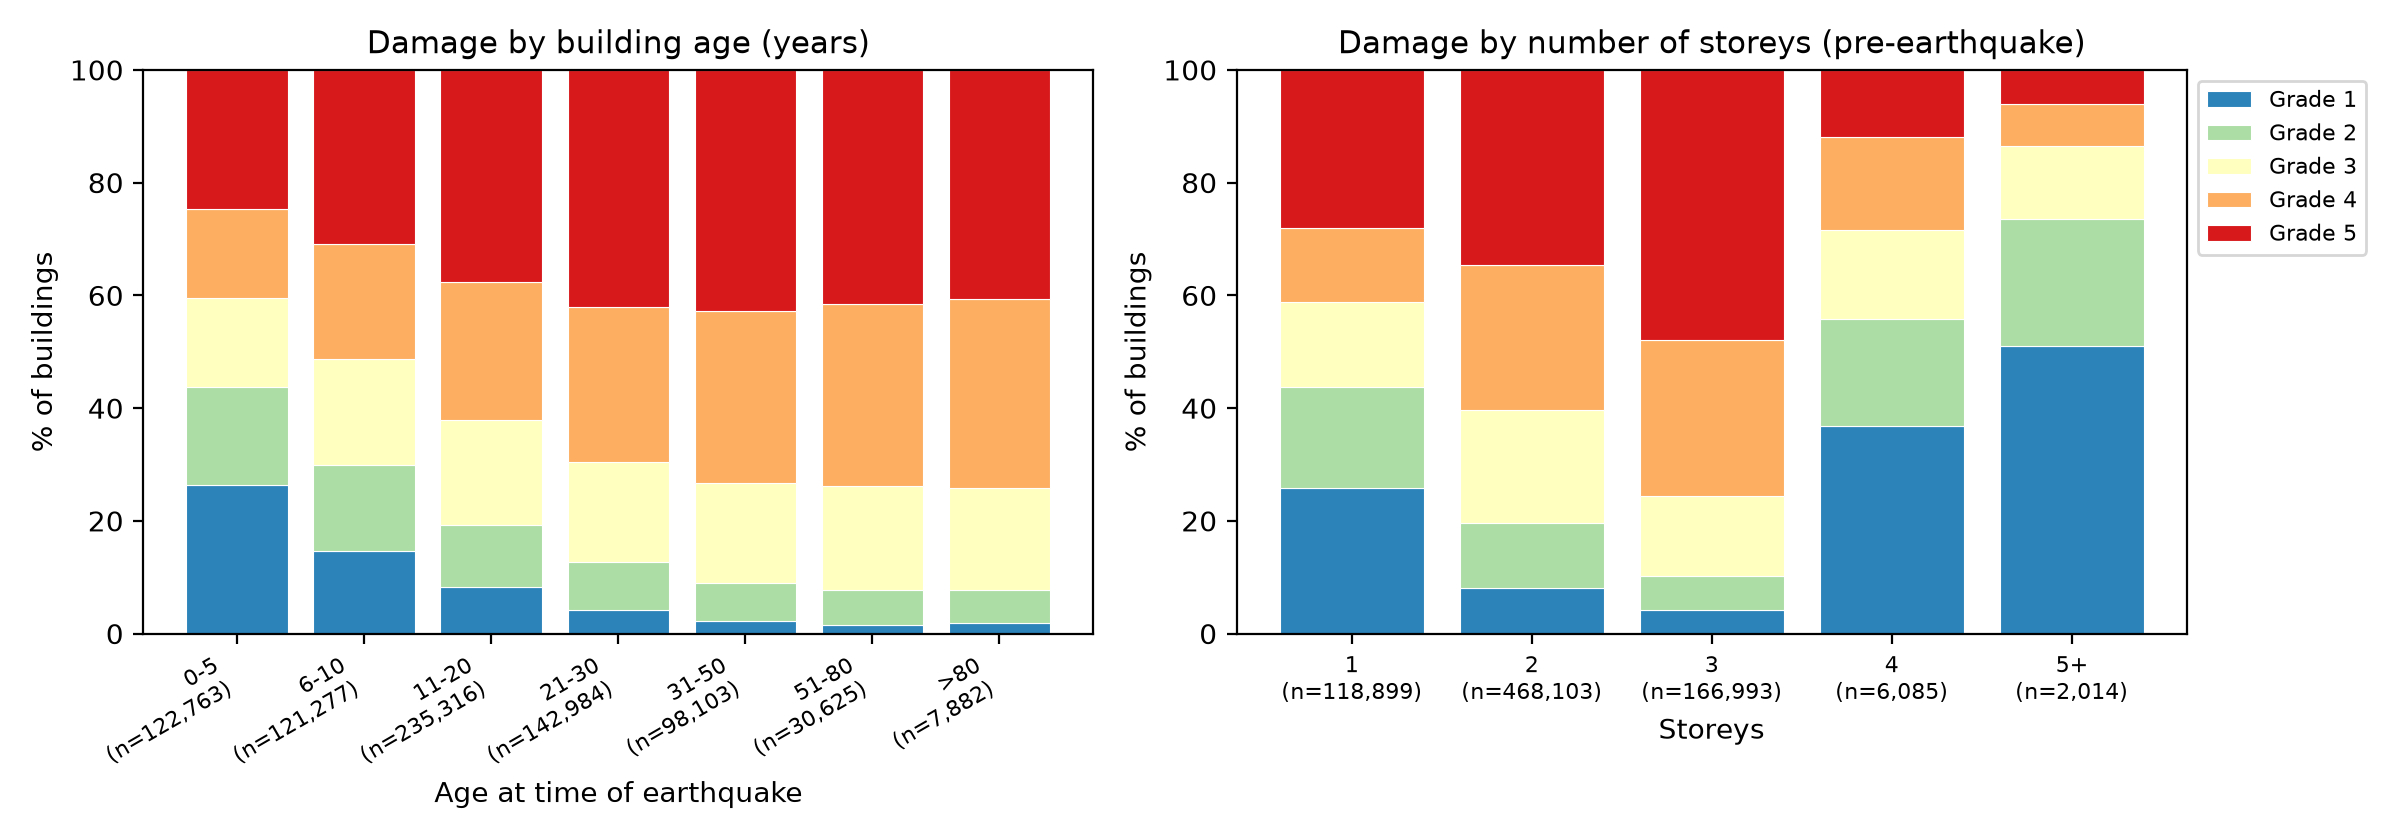

In [3]:
figs = E.make_eda_figures(df)
for p in figs.values(): display(Image(filename=str(p), width=900))

In [4]:
# Share of Grade 5 (collapse) by foundation type and by key superstructure flags
print((pd.crosstab(df['foundation_type'], df['y'], normalize='index')[4]*100).round(1).sort_values().to_string())
for c in ['has_superstructure_mud_mortar_stone','has_superstructure_rc_engineered','has_superstructure_rc_non_engineered','has_superstructure_cement_mortar_brick']:
    print(f"{c:42s} Grade-5 share = {100*(df.loc[df[c]==1,'y']==4).mean():.1f}%  (n={int((df[c]==1).sum()):,})")

foundation_type
RC                         1.6
Bamboo/Timber              9.2
Cement-Stone/Brick        15.4
Other                     35.9
Mud mortar-Stone/Brick    41.7
has_superstructure_mud_mortar_stone        Grade-5 share = 42.7%  (n=609,880)
has_superstructure_rc_engineered           Grade-5 share = 0.9%  (n=12,488)
has_superstructure_rc_non_engineered       Grade-5 share = 11.8%  (n=30,327)
has_superstructure_cement_mortar_brick     Grade-5 share = 3.5%  (n=54,510)


## 3. Train / test split and cross-validation
Stratified 80/20 split (seed 42). For runtime on CPU, 5-fold stratified CV is run on a stratified **100,000-row subsample of the training set**; final models are then evaluated once on the full 20 % test set.

In [5]:
train, test = E.split(df)
print(len(train), len(test))
out = {'cleaning': log, 'n_train': int(len(train)), 'n_test': int(len(test))}
t = time.time()
out['cv'] = E.cross_validate_models(train)
for m in ['logreg','lgbm']:
    print(m, {k: f"{v['mean']:.3f} ± {v['std']:.3f}" for k, v in out['cv'][m].items()})
print(f'CV time {time.time()-t:.0f}s'); E.save_json(out);

609675 152419


logreg {'macro_f1': '0.299 ± 0.002', 'micro_f1': '0.438 ± 0.001', 'weighted_f1': '0.340 ± 0.001', 'within_one_grade': '0.733 ± 0.002', 'accuracy': '0.438 ± 0.001'}
lgbm {'macro_f1': '0.371 ± 0.002', 'micro_f1': '0.453 ± 0.003', 'weighted_f1': '0.407 ± 0.003', 'within_one_grade': '0.772 ± 0.002', 'accuracy': '0.453 ± 0.003'}
CV time 51s


## 4. Final models on the held-out test set
* Logistic regression (multinomial; one-hot + standardised numerics) trained on a stratified 200,000-row subsample of the training set.
* LightGBM trained on the full training split (minus 10 % for early stopping), **building attributes only**.
* Ablation: LightGBM + `district_id` (a coarse proxy for location / ground-shaking intensity, which building attributes alone cannot see).

In [6]:
res, models = E.fit_final_models(train, test)
out['test'] = res; E.save_json(out)
tbl = pd.DataFrame({k: {m: round(v[m], 3) for m in ['macro_f1','micro_f1','weighted_f1','within_one_grade']} for k, v in res.items()}).T
tbl

,macro_f1,micro_f1,weighted_f1,within_one_grade
logreg,0.301,0.439,0.342,0.733
lgbm,0.391,0.474,0.426,0.781
lgbm_plus_district,0.472,0.529,0.512,0.844
majority_class,0.106,0.362,0.192,0.603


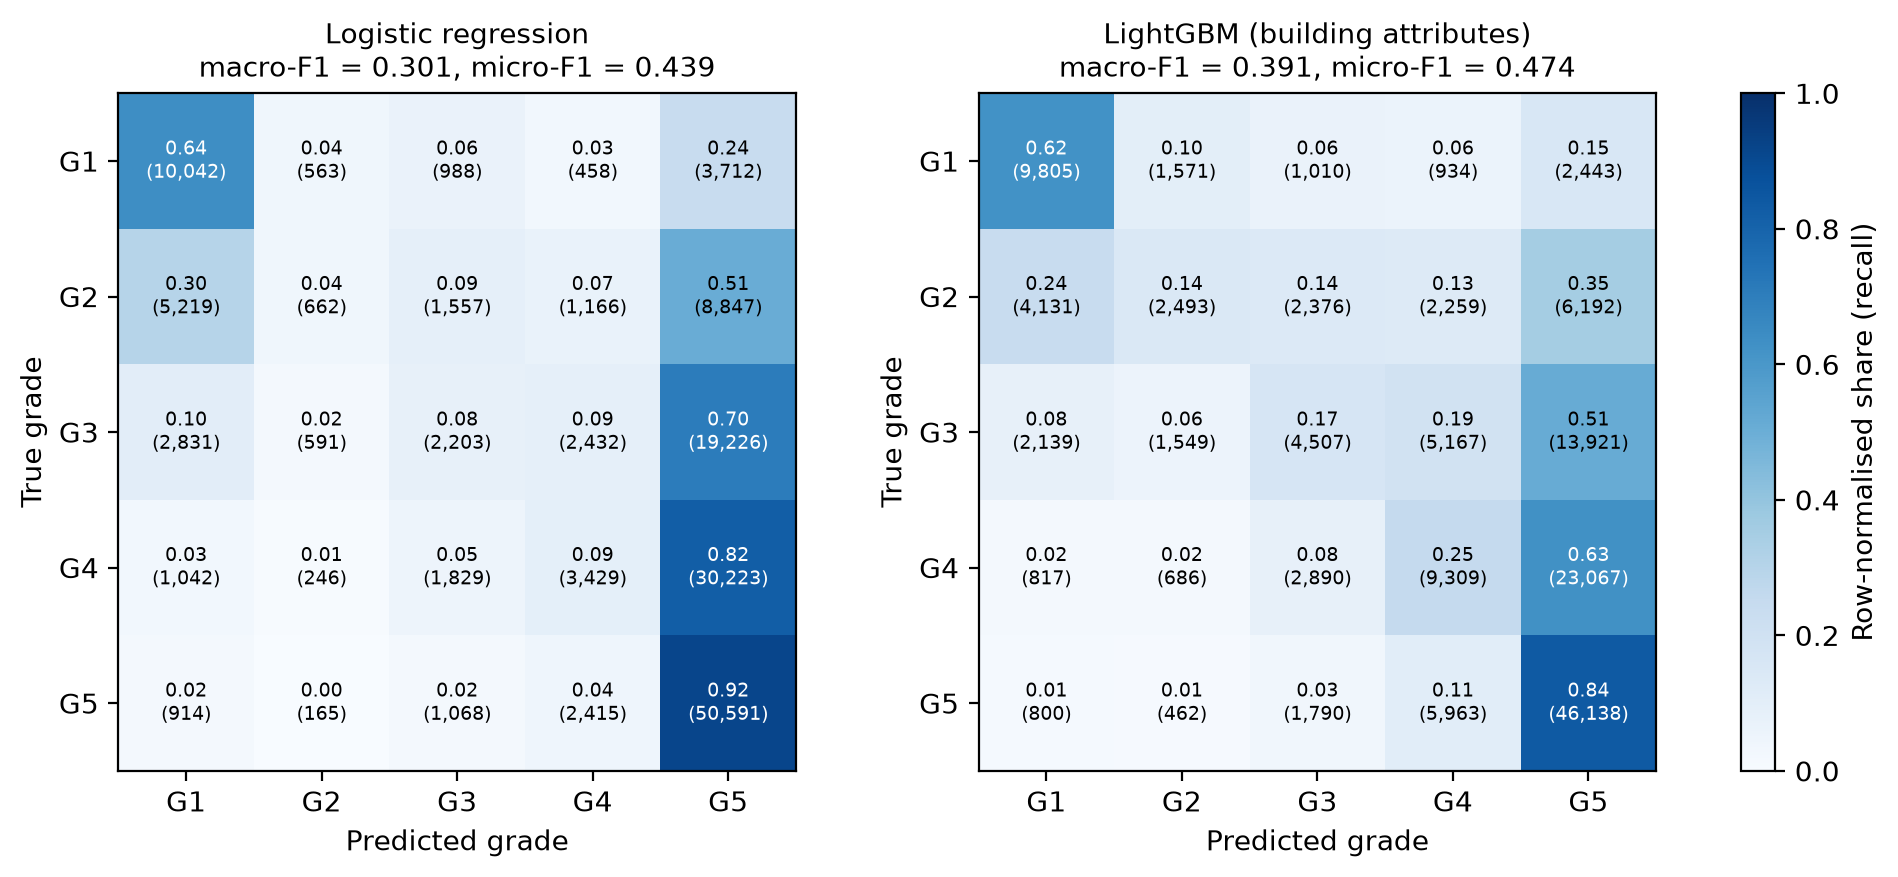

logreg
         pred G1  pred G2  pred G3  pred G4  pred G5
true G1    10042      563      988      458     3712
true G2     5219      662     1557     1166     8847
true G3     2831      591     2203     2432    19226
true G4     1042      246     1829     3429    30223
true G5      914      165     1068     2415    50591
lgbm
         pred G1  pred G2  pred G3  pred G4  pred G5
true G1     9805     1571     1010      934     2443
true G2     4131     2493     2376     2259     6192
true G3     2139     1549     4507     5167    13921
true G4      817      686     2890     9309    23067
true G5      800      462     1790     5963    46138


In [7]:
p = E.plot_confusions(res); display(Image(filename=str(p), width=900))
for k in ['logreg','lgbm']:
    print(k); print(pd.DataFrame(res[k]['confusion'], index=[f'true G{i}' for i in range(1,6)], columns=[f'pred G{i}' for i in range(1,6)]))

## 5. Interpretability — SHAP (TreeExplainer, 4,000 test rows) and permutation importance (6,000 test rows)

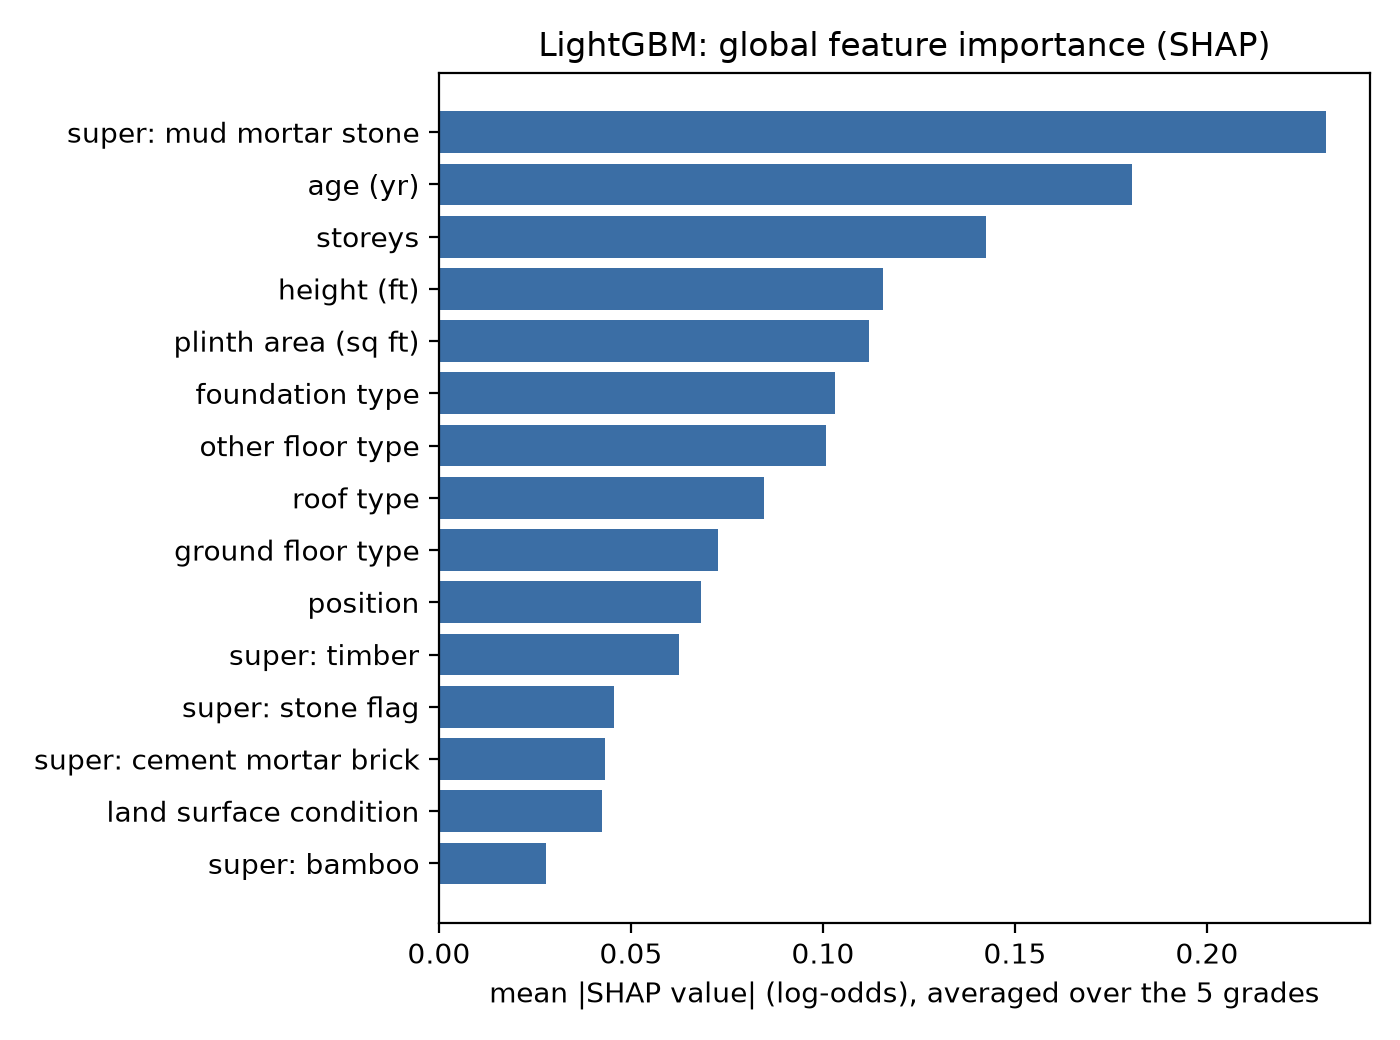

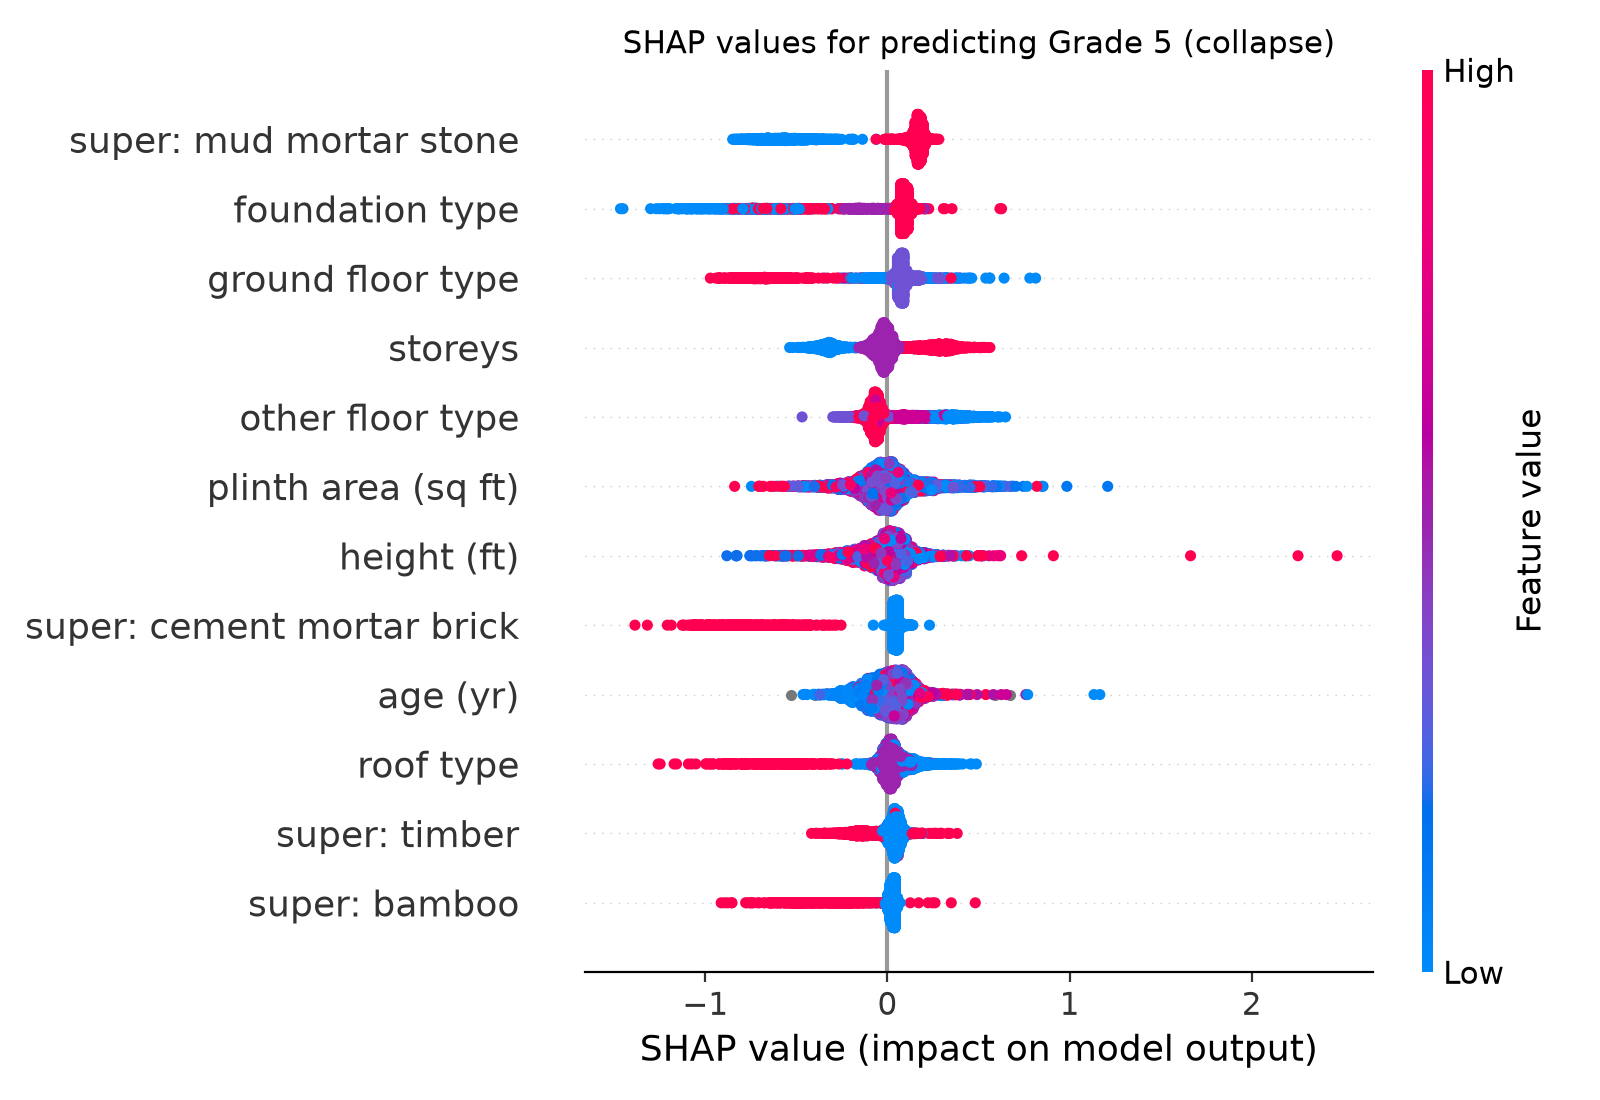

{
 "foundation_type": {
  "Bamboo/Timber": -0.798,
  "Cement-Stone/Brick": -0.112,
  "Mud mortar-Stone/Brick": 0.093,
  "Other": 0.034,
  "RC": -0.579
 },
 "roof_type": {
  "Bamboo/Timber-Heavy roof": 0.11,
  "Bamboo/Timber-Light roof": 0.014,
  "RCC/RB/RBC": -0.641
 },
 "ground_floor_type": {
  "Brick/Stone": 0.077,
  "Mud": 0.083,
  "Other": -0.158,
  "RC": -0.672,
  "Timber": -0.038
 },
 "other_floor_type": {
  "Not applicable": 0.351,
  "RCC/RB/RBC": -0.117,
  "Timber-Planck": 0.101,
  "Timber/Bamboo-Mud": -0.069
 },
 "has_superstructure_mud_mortar_stone": {
  "0": -0.577,
  "1": 0.168
 },
 "has_superstructure_rc_engineered": {
  "0": 0.015,
  "1": -0.972
 },
 "has_superstructure_rc_non_engineered": {
  "0": 0.01,
  "1": -0.247
 },
 "has_superstructure_cement_mortar_brick": {
  "0": 0.047,
  "1": -0.758
 },
 "has_superstructure_timber": {
  "0": 0.04,
  "1": -0.101
 }
}


In [8]:
out['shap'] = E.shap_analysis(models['lgbm'], test); E.save_json(out)
display(Image(filename=out['shap']['fig_importance'], width=650)); display(Image(filename=out['shap']['fig_beeswarm'], width=700))
print(json.dumps(out['shap']['grade5_mean_shap_by_level'], indent=1))

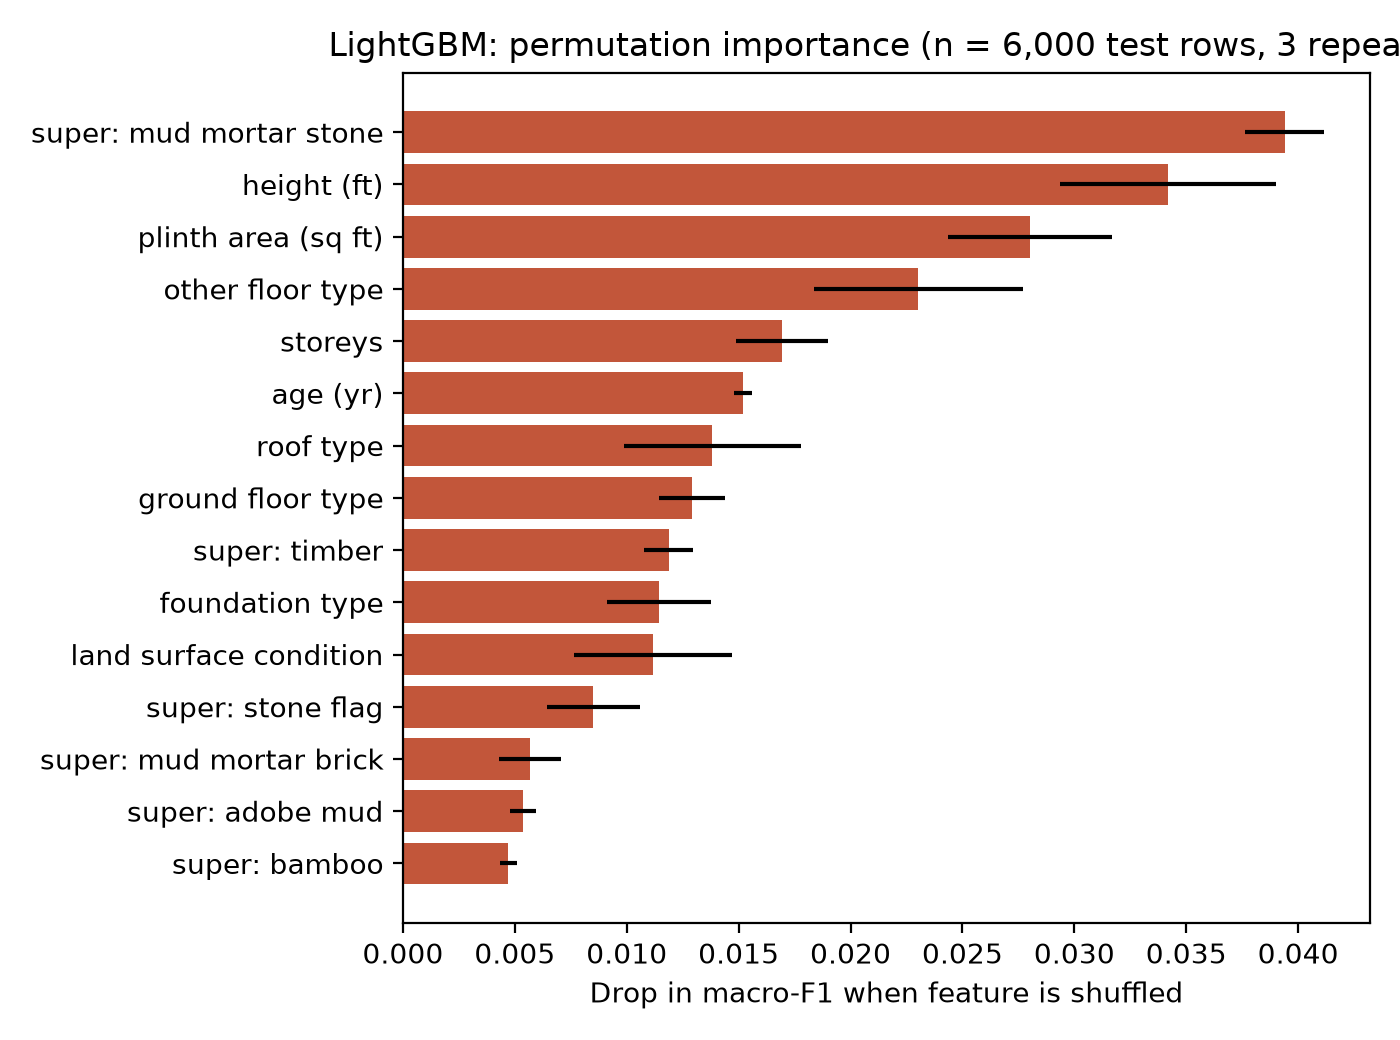

,mean,std
has_superstructure_mud_mortar_stone,0.0394,0.0018
height_ft_pre_eq,0.0342,0.0048
plinth_area_sq_ft,0.0280,0.0037
other_floor_type,0.0230,0.0047
count_floors_pre_eq,0.0169,0.0020
age_building,0.0152,0.0004
roof_type,0.0138,0.0040
ground_floor_type,0.0129,0.0015
has_superstructure_timber,0.0119,0.0011
foundation_type,0.0114,0.0023


In [9]:
out['permutation'] = E.permutation_analysis(models['lgbm'], test)
display(Image(filename=out['permutation']['fig'], width=650))
pd.DataFrame(out['permutation']['importance']).T.head(10)

In [10]:
out['runtime_seconds'] = round(time.time()-T0, 1)
E.save_json(out)
rows=[]
for k,label in [('majority_class','Majority class (always Grade 5)'),('logreg','Logistic regression'),('lgbm','LightGBM - building attributes'),('lgbm_plus_district','LightGBM + district_id')]:
    r=res[k]; rows.append({'model':label,'macro_F1':round(r['macro_f1'],3),'micro_F1':round(r['micro_f1'],3),'weighted_F1':round(r['weighted_f1'],3),'within_1_grade':round(r['within_one_grade'],3)})
pd.DataFrame(rows).to_csv('results/test_metrics.csv', index=False)
print('total runtime (s):', out['runtime_seconds']); pd.DataFrame(rows)

total runtime (s): 255.5


,model,macro_F1,micro_F1,weighted_F1,within_1_grade
0,Majority class (always Grade 5),0.106,0.362,0.192,0.603
1,Logistic regression,0.301,0.439,0.342,0.733
2,LightGBM - building attributes,0.391,0.474,0.426,0.781
3,LightGBM + district_id,0.472,0.529,0.512,0.844


## 6. Engineering interpretation (summary)
See README §Interpretation for the full discussion. In short, the model rediscovers well-known seismic vulnerability patterns: load-bearing **mud-mortar stone/brick masonry** (with mud-mortar foundations and heavy/flexible timber-mud floors) pushes predictions towards Grade 4–5, while **RC frames, RC slabs/roofs and cement-mortar masonry** push towards Grade 1–2. Location (district) adds substantial skill because it encodes shaking intensity, which building attributes cannot capture.